In [15]:
import jax
import jax.numpy as jnp
import flax.linen as nn
import optax
import optax.tree_utils as otu
from NN_class import MLP
from Pwp_class import PiecewiseLinearPolynomials
from functools import partial

def smooth_sign(x, eps = 1e-3):
  return 2*jax.nn.sigmoid(x/eps)-1

# Loss Function
def compute_loss(params, coeffs, model, tx_quad, w_quad, element_indices):
    u_quad = model.apply({'params': params}, tx_quad)
    grad_u = jax.vmap(jax.grad(lambda tx: model.apply({'params': params}, tx[None, :]).squeeze()))(tx_quad)
    u_t = grad_u[:, 0]
    u_x = grad_u[:, 1]
    k_h_quad = (coeffs[element_indices, 0] +
                coeffs[element_indices, 1] * tx_quad[:, 0] +
                coeffs[element_indices, 2] * tx_quad[:, 1])
    residual = u_t + u_quad * u_x
    sgn_term = smooth_sign(u_quad - k_h_quad)
    integrand = residual * sgn_term
    loss = jnp.sum(integrand * w_quad)
    return loss

# Optimizer Class
class MinMaxOptProb:
    def __init__(self, N_t=10, N_x=10, lr_theta=0.001, lr_kh=0.01, hidden_dims=(64, 64, 64), seed=0):
        self.pwp = PiecewiseLinearPolynomials(N_t, N_x)
        self.lr_theta = lr_theta
        self.lr_kh = lr_kh
        self.model = MLP(hidden_dims=hidden_dims)
        key = jax.random.PRNGKey(seed)
        self.params = self.model.init(key, jnp.ones((1, 2)))['params']
        # Define optimizer
        self.opt_theta = optax.adam(self.lr_theta)
        self.opt_kh = optax.scale_by_lbfgs()
        self.opt_state_theta = self.opt_theta.init(self.params)
        self.opt_state_kh = self.opt_kh.init(self.pwp.coeffs)

    def loss(self, params, coeffs):
        return compute_loss(params, coeffs, self.model, self.pwp.tx_quad, self.pwp.w_quad, self.pwp.element_indices)

    def train_step(self):
        loss_value, (grad_params, grad_coeffs) = jax.value_and_grad(self.loss, argnums=(0, 1))(self.params, self.pwp.coeffs)
        updates_kh, self.opt_state_kh = self.opt_kh.update(grad_coeffs, self.opt_state_kh, self.pwp.coeffs)
        self.pwp.coeffs = self.pwp.coeffs + self.lr_kh * updates_kh
        # self.pwp.coeffs = self.pwp.coeffs + self.lr_kh * grad_coeffs
        updates, self.opt_state_theta = self.opt_theta.update(grad_params, self.opt_state_theta)
        self.params = optax.apply_updates(self.params, updates)
        return self.loss(self.params, self.pwp.coeffs)


In [2]:
# Training Loop
if __name__ == "__main__":
    optimizer = MinMaxOptProb(
        N_t=100,
        N_x=100,
        lr_theta=0.02,
        lr_kh=0.02,
        hidden_dims=(64, 64),
        seed=0
    )
    num_iterations = 1000
    for iter in range(num_iterations):
        loss = optimizer.train_step()
        if iter % 100 == 0:
            print(f"Iteration {iter}, Loss: {loss:.6f}")

W0000 00:00:1741517855.008698 37139911 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1741517855.022721 37139911 service.cc:145] XLA service 0x6000001d0a00 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1741517855.022734 37139911 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1741517855.024057 37139911 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1741517855.024068 37139911 mps_client.cc:384] XLA backend will use up to 22906109952 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M2 Pro
Iteration 0, Loss: 1.244302


KeyboardInterrupt: 

In [13]:
# Loss Function
def test_kh_loss(coeffs, tx_quad, w_quad, element_indices):
    k_h_quad = (coeffs[element_indices, 0] +
                coeffs[element_indices, 1] * tx_quad[:, 0] +
                coeffs[element_indices, 2] * tx_quad[:, 1])
    residual = jnp.sin(2*jnp.pi*tx_quad[:, 0] + tx_quad[:, 1]) - k_h_quad
    loss = jnp.sum(residual**2)
    return loss

def test_u_theta_loss(params, model, tx_quad, w_quad, element_indices):
    u_quad = model.apply({'params': params}, tx_quad)
    residual = u_quad - jnp.sin(2*(2*jnp.pi*tx_quad[:, 0] + tx_quad[:, 1]))
    integrand = residual
    loss = jnp.sum(residual**2)
    return loss

# Optimizer Class
class MinMaxOptProb:
    def __init__(self, N_t=10, N_x=10, lr_theta=0.001, lr_kh=0.01, hidden_dims=(64, 64, 64), seed=0):
        self.pwp = PiecewiseLinearPolynomials(N_t, N_x)
        self.lr_theta = lr_theta
        self.lr_kh = lr_kh
        self.model = MLP(hidden_dims=hidden_dims)
        key = jax.random.PRNGKey(seed)
        self.params = self.model.init(key, jnp.ones((1, 2)))['params']
        self.opt_theta = optax.adam(self.lr_theta)
        self.opt_state_theta = self.opt_theta.init(self.params)
        self.opt_kh = optax.adam(self.lr_kh)
        self.opt_state_theta = self.opt_theta.init(self.params)
        self.opt_state_kh = self.opt_theta.init(self.pwp.coeffs)

    def loss(self, params, coeffs):
        return test_kh_loss(coeffs, self.pwp.tx_quad, self.pwp.w_quad, self.pwp.element_indices)
        # return test_u_theta_loss(params, self.model, self.pwp.tx_quad, self.pwp.w_quad, self.pwp.element_indices)

    def train_step(self):
        grad_params, grad_coeffs = jax.grad(self.loss, argnums=(0, 1))(self.params, self.pwp.coeffs)
        self.pwp.coeffs = self.pwp.coeffs - self.lr_kh * grad_coeffs
        # updates, self.opt_state_theta = self.opt_theta.update(grad_params, self.opt_state_theta)
        # self.params = optax.apply_updates(self.params, updates)
        return self.loss(self.params, self.pwp.coeffs)

# # Optimizer Class
# class MinMaxOptProb:
#     def __init__(self, N_t=10, N_x=10, lr_theta=0.001, lr_kh=0.01, hidden_dims=(64, 64, 64), seed=0):
#         self.pwp = PiecewiseLinearPolynomials(N_t, N_x)
#         self.lr_theta = lr_theta
#         self.lr_kh = lr_kh
#         self.model = MLP(hidden_dims=hidden_dims)
#         key = jax.random.PRNGKey(seed)
#         self.params = self.model.init(key, jnp.ones((1, 2)))['params']
#         # Define optimizers
#         self.opt_theta = optax.adam(self.lr_theta)
#         self.opt_kh = optax.lbfgs()
#         self.opt_state_theta = self.opt_theta.init(self.params)
#         self.opt_state_kh = self.opt_kh.init(self.pwp.coeffs)
#         self.max_iter = 2

#     def compute_loss(self, params, coeffs):
#         """Wrapper for the full loss function."""
#         return compute_loss(params, coeffs, self.model, self.pwp.tx_quad, self.pwp.w_quad, self.pwp.element_indices)

#     def LBFGS_step(self, carry, loss_fn):
#         """
#         Perform one LBFGS step using the provided loss function.
        
#         Args:
#             carry: Tuple of (params, optimizer_state)
#             loss_fn: Loss function to optimize
#         """
#         params, state = carry
#         value, grad = jax.value_and_grad(loss_fn)(params)
#         updates, state = self.opt_kh.update(
#             grad, state, params, value=value, grad=grad, value_fn=loss_fn
#         )
#         params = optax.apply_updates(params, updates)
#         return (params, state)

#     def LBFGS_continuing_criterion(self, carry):
#         """Check if LBFGS should continue."""
#         _, state = carry
#         iter_num = otu.tree_get(state, 'count')
#         return iter_num < self.max_iter

#     def train_step(self):
#         """
#         Perform one training step: maximize loss w.r.t. coeffs using LBFGS,
#         then minimize loss w.r.t. params using Adam.
#         """
#         # Define loss for k_h optimization (maximize loss -> minimize -loss)
#         def loss_kh(coeffs):
#             return -self.compute_loss(self.params, coeffs)

#         # JIT-compile the LBFGS step with the current loss_kh
#         value_and_grad_kh = jax.value_and_grad(loss_kh)
#         lbfgs_step = partial(self.LBFGS_step, loss_fn=loss_kh)

#         # Run LBFGS optimization for k_h
#         LBFGS_carry = (self.pwp.coeffs, self.opt_state_kh)
#         self.pwp.coeffs, self.opt_state_kh = jax.lax.while_loop(
#             self.LBFGS_continuing_criterion,
#             lbfgs_step,
#             LBFGS_carry
#         )

#         # Define loss for u_theta optimization (minimize loss)
#         def loss_theta(params):
#             return self.compute_loss(params, self.pwp.coeffs)

#         # Optimize u_theta with Adam
#         value, grad_params = jax.value_and_grad(loss_theta)(self.params)
#         updates, self.opt_state_theta = self.opt_theta.update(grad_params, self.opt_state_theta)
#         self.params = optax.apply_updates(self.params, updates)

#         # Return the current loss
#         return self.compute_loss(self.params, self.pwp.coeffs)


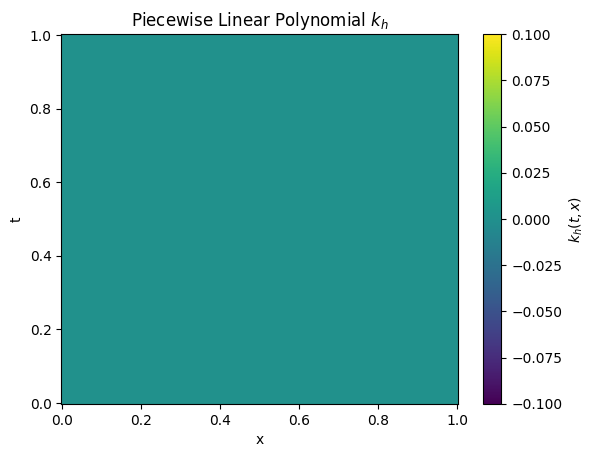

Iteration 0, Loss: 138.393860
Iteration 50, Loss: 19.905230
Iteration 100, Loss: 19.537529
Iteration 150, Loss: 19.177238
Iteration 200, Loss: 18.824200
Iteration 250, Loss: 18.478258
Iteration 300, Loss: 18.139261
Iteration 350, Loss: 17.807060
Iteration 400, Loss: 17.481510
Iteration 450, Loss: 17.162462
Iteration 500, Loss: 16.849789
Iteration 550, Loss: 16.543344
Iteration 600, Loss: 16.243000
Iteration 650, Loss: 15.948626
Iteration 700, Loss: 15.660097
Iteration 750, Loss: 15.377285
Iteration 800, Loss: 15.100072
Iteration 850, Loss: 14.828337
Iteration 900, Loss: 14.561964
Iteration 950, Loss: 14.300841


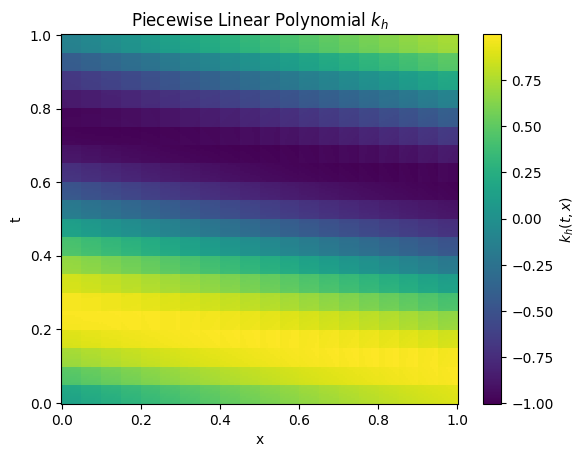

In [14]:
# Training Loop
if __name__ == "__main__":
    optProb = MinMaxOptProb(
        N_t=20,
        N_x=20,
        lr_theta=0.05,
        lr_kh=0.05,
        hidden_dims=(64, 64),
        seed=0
    )
    num_iterations = 1000
    plot_kh(optProb.pwp, M_factor=10)
    for iter in range(num_iterations):
        loss = optProb.train_step()
        if iter % 50 == 0:
            print(f"Iteration {iter}, Loss: {loss:.6f}")
    plot_kh(optProb.pwp, M_factor=10)
    # plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)

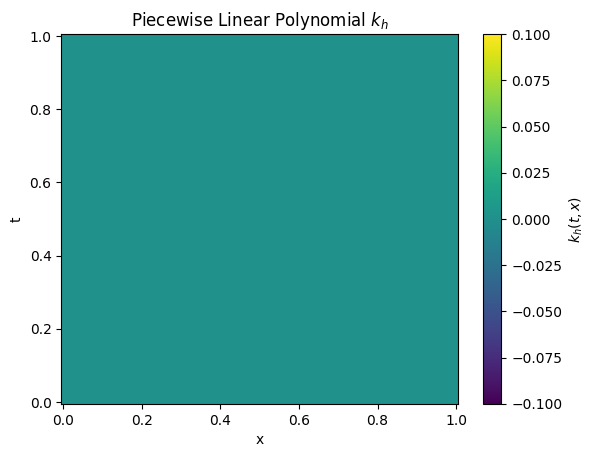

Iteration 0, Loss: 524.407166
Iteration 100, Loss: 22.151386
Iteration 200, Loss: 18.582827
Iteration 300, Loss: 15.609524
Iteration 400, Loss: 13.129788
Iteration 500, Loss: 11.059594
Iteration 600, Loss: 9.329465
Iteration 700, Loss: 7.881926
Iteration 800, Loss: 6.669410
Iteration 900, Loss: 5.652522


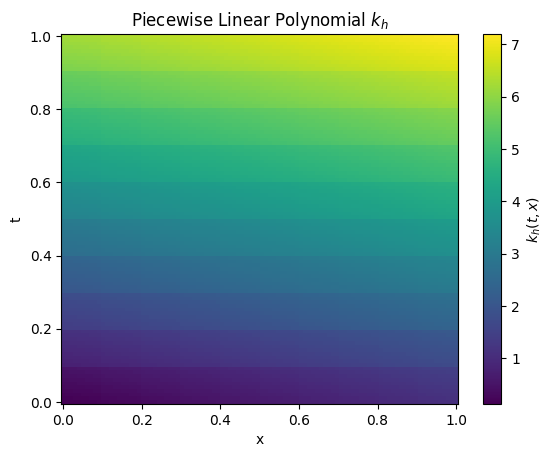

In [11]:
# Training Loop
if __name__ == "__main__":
    optProb = MinMaxOptProb(
        N_t=10,
        N_x=10,
        lr_theta=0.05,
        lr_kh=0.05,
        hidden_dims=(64, 64),
        seed=0
    )
    num_iterations = 1000
    plot_kh(optProb.pwp, M_factor=10)
    for iter in range(num_iterations):
        loss = optProb.train_step()
        if iter % 100 == 0:
            print(f"Iteration {iter}, Loss: {loss:.6f}")
    plot_kh(optProb.pwp, M_factor=10)
    # plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)

In [4]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

def plot_kh(pwp, M_factor=10):
    """
    Plot the piecewise linear polynomial function k_h over [0,1]^2.

    Args:
        pwp: Object with attributes N_t (int), N_x (int), and coeffs (jnp.ndarray).
             - N_t: Number of intervals in the t-direction.
             - N_x: Number of intervals in the x-direction.
             - coeffs: JAX array of shape (N_t * N_x, 3) containing coefficients [a_K, b_K, c_K].
        M_factor: Integer factor to refine the plotting grid (default: 10).
    """
    # Extract tessellation parameters
    N_t, N_x = pwp.N_t, pwp.N_x
    tau = 1.0 / N_t  # Element size in t-direction
    hx = 1.0 / N_x   # Element size in x-direction

    # Create a fine grid for evaluation
    M_t, M_x = N_t * M_factor, N_x * M_factor
    t_grid = jnp.linspace(0, 1, M_t)  # Shape: (M_t,)
    x_grid = jnp.linspace(0, 1, M_x)  # Shape: (M_x,)

    # Generate 2D coordinate arrays
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Determine element indices for each grid point
    i = jnp.floor(t / tau).astype(int)  # Shape: (M_t, M_x)
    j = jnp.floor(x / hx).astype(int)   # Shape: (M_t, M_x)
    i = jnp.clip(i, 0, N_t - 1)        # Ensure indices are within bounds
    j = jnp.clip(j, 0, N_x - 1)

    # Compute element index K = i * N_x + j
    K = i * N_x + j  # Shape: (M_t, M_x)

    # Extract coefficients for each element at corresponding grid points
    a_K = pwp.coeffs[K, 0]  # Shape: (M_t, M_x)
    b_K = pwp.coeffs[K, 1]
    c_K = pwp.coeffs[K, 2]

    # Evaluate k_h(t, x) = a_K + b_K * t + c_K * x
    kh_values = a_K + b_K * t + c_K * x  # Shape: (M_t, M_x)

    # Plot using pcolormesh
    plt.pcolormesh(x_grid, t_grid, kh_values, shading='nearest')
    plt.colorbar(label='$k_h(t, x)$')
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Piecewise Linear Polynomial $k_h$')
    plt.show()

# Example usage (assuming pwp is defined):

# plot_kh(optProb.pwp, M_factor=10)

In [4]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

def plot_difference(g, pwp, M_factor=10):
    """
    Plot the difference between g and k_h over [0,1]^2.

    Args:
        g: Callable that takes a JAX array of shape (N, 2) and returns shape (N,).
           Each row of the input is [t, x].
        pwp: Object with attributes N_t (int), N_x (int), and coeffs (array of shape (N_t * N_x, 3)).
        M_factor: Integer factor to refine the plotting grid (default: 10).
    """
    # Grid parameters from pwp
    N_t, N_x = pwp.N_t, pwp.N_x
    tau = 1.0 / N_t  # Step size in t
    hx = 1.0 / N_x   # Step size in x

    # Create fine grid
    M_t, M_x = N_t * M_factor, N_x * M_factor
    t_grid = jnp.linspace(0, 1, M_t)
    x_grid = jnp.linspace(0, 1, M_x)
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')

    # Compute k_h values
    i = jnp.floor(t / tau).astype(int)
    j = jnp.floor(x / hx).astype(int)
    i = jnp.clip(i, 0, N_t - 1)  # Ensure indices stay within bounds
    j = jnp.clip(j, 0, N_x - 1)
    K = i * N_x + j  # Flatten indices
    a_K = pwp.coeffs[K, 0]  # Intercept
    b_K = pwp.coeffs[K, 1]  # t coefficient
    c_K = pwp.coeffs[K, 2]  # x coefficient
    kh_values = a_K + b_K * t + c_K * x  # Piecewise linear evaluation

    # Evaluate g on the grid
    tx_points = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)
    g_values = g(tx_points).reshape(M_t, M_x)  # Evaluate and reshape to (M_t, M_x)

    # Compute difference
    diff = g_values - kh_values

    # Plot the difference as a heatmap
    plt.pcolormesh(x_grid, t_grid, diff, shading='nearest', cmap='coolwarm')
    plt.colorbar(label='$g(t, x) - k_h(t, x)$')
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Difference between $g$ and $k_h$')
    plt.show()

# Example usage:
# Define a sample g function (e.g., a simple expression or neural network)
def g(tx):
    t, x = tx[:, 0], tx[:, 1]
    return 2*jnp.pi*t + x # Example function

# Assuming pwp is an object with N_t, N_x, and coeffs defined
# plot_difference(g, pwp, M_factor=10)

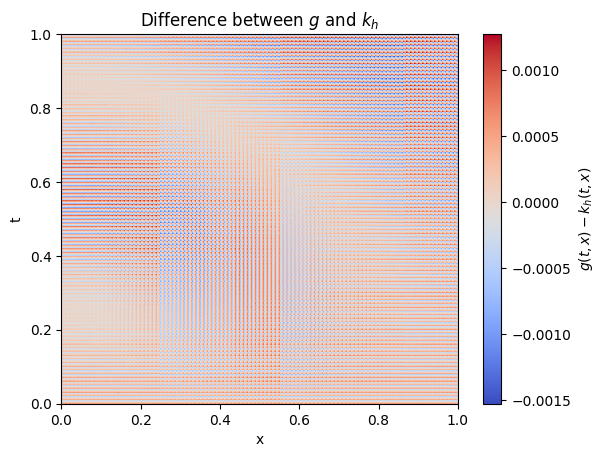

In [36]:
plot_difference(g, optProb.pwp, M_factor=10)

In [4]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
from flax import linen as nn


# Function to plot u_theta
def plot_u_theta(model, params, M_t=100, M_x=100):
    """
    Plot the neural network function u_theta over [0,1]^2.

    Args:
        model: Flax model instance representing u_theta.
        params: Parameters (pytree) of the neural network.
        M_t: Number of grid points in the t-direction (default: 100).
        M_x: Number of grid points in the x-direction (default: 100).
    """
    # Create a grid for t and x
    t_grid = jnp.linspace(0, 1, M_t)
    x_grid = jnp.linspace(0, 1, M_x)
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Flatten the grid for batch evaluation
    tx_points = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

    # Evaluate u_theta on the grid points
    u_values = model.apply({'params': params}, tx_points)  # Shape: (M_t * M_x, 1)
    u_values = u_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)

    # Create the plot
    plt.figure(figsize=(8, 6))
    plt.pcolormesh(x_grid, t_grid, u_values, shading='nearest', cmap='viridis')
    plt.colorbar(label='$u_\\theta(t, x)$')
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Neural Network Function $u_\\theta$')
    plt.show()

# # Example usage
# if __name__ == "__main__":
#     # Initialize the model and parameters
#     model = SimpleNN()
#     key = jax.random.PRNGKey(0)
#     sample_input = jnp.ones((1, 2))  # Dummy input with shape (batch_size, 2) for t, x
#     params = model.init(key, sample_input)['params']

#     # Plot the function
#     plot_u_theta(model, params, M_t=100, M_x=100)

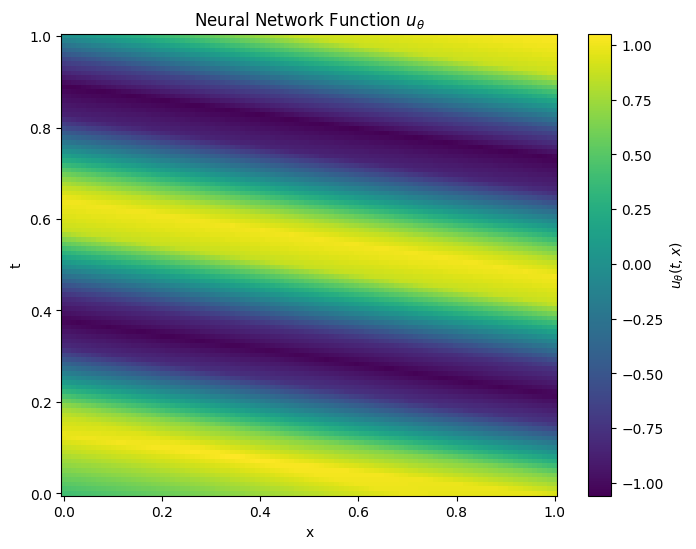

In [5]:
plot_u_theta(optProb.model, optProb.params, M_t=100, M_x=100)

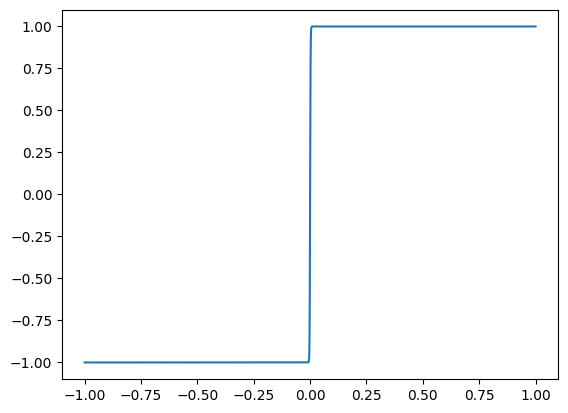

In [17]:


arr = jnp.arange(100000)/50000 - 1
plt.plot(arr, smooth_sign(arr))

In [3]:
from jax.scipy.optimize import minimize as jax_minimize

# Loss Function
def test_kh_loss(coeffs, tx_quad, w_quad, element_indices):
    k_h_quad = (coeffs[element_indices, 0] +
                coeffs[element_indices, 1] * tx_quad[:, 0] +
                coeffs[element_indices, 2] * tx_quad[:, 1])
    residual = 2*jnp.pi*tx_quad[:, 0] + tx_quad[:, 1] - k_h_quad
    loss = jnp.sum(residual**2)
    return loss



class MinMaxOptimizer:
    """Class to manage min-max optimization with L-BFGS for k_h."""

    def __init__(self, N_t=10, N_x=10, lr_theta=0.001, hidden_dims=(64, 64), seed=0, maxiter_lbfgs=10):
        """
        Initialize the optimizer.

        Args:
            N_t: Number of intervals in t-direction.
            N_x: Number of intervals in x-direction.
            lr_theta: Learning rate for θ (gradient descent).
            hidden_dims: Hidden layer sizes for the MLP.
            seed: Random seed for reproducibility.
            maxiter_lbfgs: Max L-BFGS iterations per step.
        """
        self.N_t = N_t
        self.N_x = N_x
        self.lr_theta = lr_theta
        self.maxiter_lbfgs = maxiter_lbfgs
        self.N_elements = N_t * N_x
        self.pwp = PiecewiseLinearPolynomials(N_t, N_x)

        # Initialize neural network (θ)
        self.model = MLP(hidden_dims=hidden_dims)
        key = jax.random.PRNGKey(seed)
        self.params = self.model.init(key, jnp.ones((1, 2)))['params']

        # Optimizer for θ (using Adam)
        self.opt_theta = optax.adam(self.lr_theta)
        self.opt_state_theta = self.opt_theta.init(self.params)

    def loss(self, params, coeffs):
        # return compute_loss(params, coeffs, self.model, self.pwp.tx_quad, self.pwp.w_quad, self.pwp.element_indices)
        # return test_u_theta_loss(params, self.model, self.pwp.tx_quad, self.pwp.w_quad, self.pwp.element_indices)
        return test_kh_loss(coeffs, self.pwp.tx_quad, self.pwp.w_quad, self.pwp.element_indices)

    def neg_loss_for_kh(self, coeffs, params):
        """Negative loss for L-BFGS optimization of k_h."""
        return self.loss(params, coeffs)

    def train_step(self):
        """Perform one iteration of alternating optimization."""
        # Step 1: Optimize k_h using L-BFGS to maximize loss (minimize -loss)
        def objective(coeffs):
            return self.neg_loss_for_kh(coeffs, self.params)

        grad_objective = jax.grad(objective)
        initial_coeffs = self.pwp.coeffs.flatten()

        # Run L-BFGS
        result = jax_minimize(
            fun=objective,
            x0=initial_coeffs,
            method='L-BFGS',
            options={'maxiter': self.maxiter_lbfgs}
        )
        self.pwp.coeffs = result.x.reshape(self.N_elements, 3)

        # Step 2: Update θ using gradient descent
        # grad_params = jax.grad(self.loss, argnums=0)(self.params, self.pwp.coeffs)
        # updates, self.opt_state_theta = self.opt_theta.update(grad_params, self.opt_state_theta)
        # self.params = optax.apply_updates(self.params, updates)

        return self.loss(self.params, self.pwp.coeffs)

# Example usage
if __name__ == "__main__":
    optimizer = MinMaxOptimizer(N_t=10, N_x=10, lr_theta=0.001, hidden_dims=(64, 64), seed=0, maxiter_lbfgs=10)
    for iter in range(100):
        loss = optimizer.train_step()
        if iter % 10 == 0:
            print(f"Iteration {iter}, Loss: {loss:.6f}")

ValueError: Method L-BFGS not recognized

In [8]:
def step(carry):
    i = carry
    print(i)
    return i+1

def continuing_criterion(carry):
    i = carry
    return i < 10

init_carry = 0
final_i = jax.lax.while_loop(
      continuing_criterion, step, init_carry
  )

Traced<ShapedArray(int32[], weak_type=True)>with<DynamicJaxprTrace>


In [9]:
final_i

Array(10, dtype=int32, weak_type=True)

In [2]:
from typing import NamedTuple

import chex
import jax
import jax.numpy as jnp
import jax.random as jrd

import optax
import optax.tree_utils as otu

def run_opt(init_params, fun, opt, max_iter, tol):
  value_and_grad_fun = optax.value_and_grad_from_state(fun)

  def step(carry):
    params, state = carry
    value, grad = value_and_grad_fun(params, state=state)
    updates, state = opt.update(
        grad, state, params, value=value, grad=grad, value_fn=fun
    )
    params = optax.apply_updates(params, updates)
    return params, state

  def continuing_criterion(carry):
    _, state = carry
    iter_num = otu.tree_get(state, 'count')
    grad = otu.tree_get(state, 'grad')
    err = otu.tree_l2_norm(grad)
    return (iter_num == 0) | ((iter_num < max_iter) & (err >= tol))

  init_carry = (init_params, opt.init(init_params))
  final_params, final_state = jax.lax.while_loop(
      continuing_criterion, step, init_carry
  )
  return final_params, final_state

def fun(w):
  return jnp.sum(100.0 * (w[1:] - w[:-1] ** 2) ** 2 + (1.0 - w[:-1]) ** 2)

opt = optax.lbfgs()
init_params = jnp.zeros((8,))
print(
    f'Initial value: {fun(init_params):.2e} '
    f'Initial gradient norm: {otu.tree_l2_norm(jax.grad(fun)(init_params)):.2e}'
)
final_params, _ = run_opt(init_params, fun, opt, max_iter=100, tol=1e-3)
print(
    f'Final value: {fun(final_params):.2e}, '
    f'Final gradient norm: {otu.tree_l2_norm(jax.grad(fun)(final_params)):.2e}'
)

XlaRuntimeError: UNIMPLEMENTED: default_memory_space is not supported.

W0000 00:00:1741526454.716419 37149288 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1741526454.737037 37149288 service.cc:145] XLA service 0x600000cf4000 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1741526454.737212 37149288 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1741526454.739026 37149288 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1741526454.739041 37149288 mps_client.cc:384] XLA backend will use up to 22906109952 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M2 Pro
Initial value: 7.00e+00 Initial gradient norm: 5.29e+00
